<a href="https://colab.research.google.com/github/ekaterinagolowatenko/Neural_network/blob/main/cnn_svd_copy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# import imageio as im
from google.colab import drive
import torch
import torch.nn as nn
from PIL import Image
import torch.optim as optim
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim
import os
import glob #для нахождения файлов по шаблону
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim
from skimage.feature import canny, blob_dog, blob_log
from skimage.measure import label, regionprops
import warnings

In [ ]:
warnings.filterwarnings('ignore') #евгений александрович, если вы это читаете, то в будущем я планировала добавить аугментации для изображений, тк 5 изображений и 1125 патчей — это относительно небольшой объем для обучения глубоких нейронных сетей и усложнить архитектуру cnn

In [ ]:
drive.mount('/content/drive')
# dataset_path = ('/content/drive/MyDrive/datasets/Astronomical_Image_Denoising')
# clean_path = ('/content/drive/MyDrive/datasets/Astronomical_Image_Denoising/data/clean/datainte23.npy')
# data = np.load(clean_path) #массив np

# print("Исходные данные:")
# print(f"  Форма: {data.shape}")
# print(f"  Тип: {data.dtype}")
# print(f"  Мин: {data.min():.2e}")
# print(f"  Макс: {data.max():.2e}")

clean_folder = '/content/drive/MyDrive/datasets/Astronomical_Image_Denoising/data/clean/'
npy_files = sorted(glob.glob(os.path.join(clean_folder, '*.npy'))) #сортирует по алфавиту все файлы с .npy полные пути к картинкам
print(f"всего файлов: {len(npy_files)}")
all_images = [] #список из всех 5 изображений
for i, file_path in enumerate(npy_files): #file_path строка с путем к файлу. временное имя
    filename = os.path.basename(file_path) #вытсаскивает только имя файла без полного пути os.path.basename только после последнего /
    print(f"\nЗагрузка {i+1}/{len(npy_files)}: {filename}")

    data = np.load(file_path)

    if len(data.shape) == 3:
        print(f" {data.shape})")
        for j in range(data.shape[0]): #стек с 1 объектом
            all_images.append(data[j])
    elif len(data.shape) == 2:
        print(f"{data.shape}")
        all_images.append(data)
    print(f"загружено: {len(all_images)} изображений")
if len(all_images) > 0: #проверка на пустоту
    print(f"Размер первого изображения: {all_images[0].shape}")

Mounted at /content/drive
всего файлов: 5

Загрузка 1/5: datainte23.npy
 (1, 519, 519))
загружено: 1 изображений

Загрузка 2/5: datainte24.npy
 (1, 519, 519))
загружено: 2 изображений

Загрузка 3/5: datainte25.npy
 (1, 519, 519))
загружено: 3 изображений

Загрузка 4/5: datainte26.npy
 (1, 519, 519))
загружено: 4 изображений

Загрузка 5/5: datainte27.npy
 (1, 519, 519))
загружено: 5 изображений
Размер первого изображения: (519, 519)



Обработка 1 из 5...

После нормализации:
  Мин: 0.0000
  Макс: 1.0000


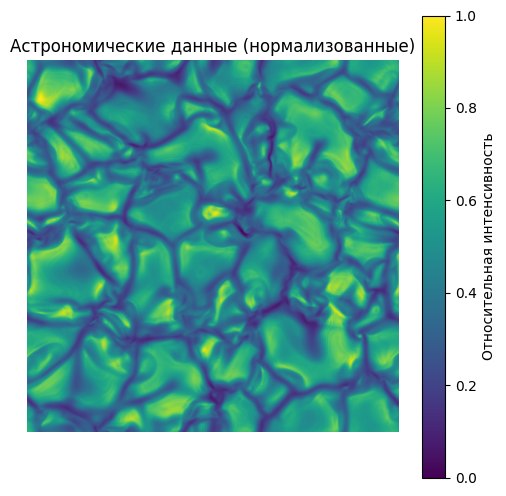

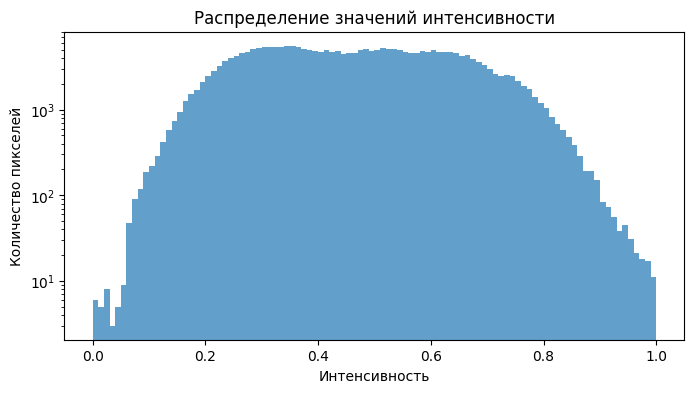

Создано 225 патчей

Обработка 2 из 5...
Создано 225 патчей

Обработка 3 из 5...
Создано 225 патчей

Обработка 4 из 5...
Создано 225 патчей

Обработка 5 из 5...
Создано 225 патчей
ИТОГО:
  Изображений: 5
  Всего патчей: 1125
  Патчей на изображение: ~225


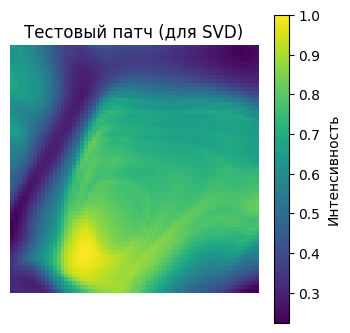

2)применяем svd к патчу
U: (64, 64)
S: (64,)
Vt: (64, 64)
Автоматически подобранный k: 2
patch_svd создан с k=2
  Размер: (64, 64)
  Диапазон: [0.1619, 0.9715]

Зашумлённый патч (для сравнения):
PSNR: 20.02 dB
SSIM: 0.3227

 Улучшение после SVD:
PSNR: +1.98 dB
SSIM: +0.4448

Первые 10 сингулярных значений:
S[0] = 40.261177
S[1] = 5.540050
S[2] = 4.249088
S[3] = 2.269177
S[4] = 1.283994
S[5] = 0.748266
S[6] = 0.444047
S[7] = 0.276187
S[8] = 0.240449
S[9] = 0.162906

Последние 10 сингулярных значений:
  S[54] = 0.00268466
  S[55] = 0.00233212
  S[56] = 0.00219839
  S[57] = 0.00168814
  S[58] = 0.00128309
  S[59] = 0.00092247
  S[60] = 0.00061804
  S[61] = 0.00038572
  S[62] = 0.00022748
  S[63] = 0.00012996
3) визуализируем сингулярные значения


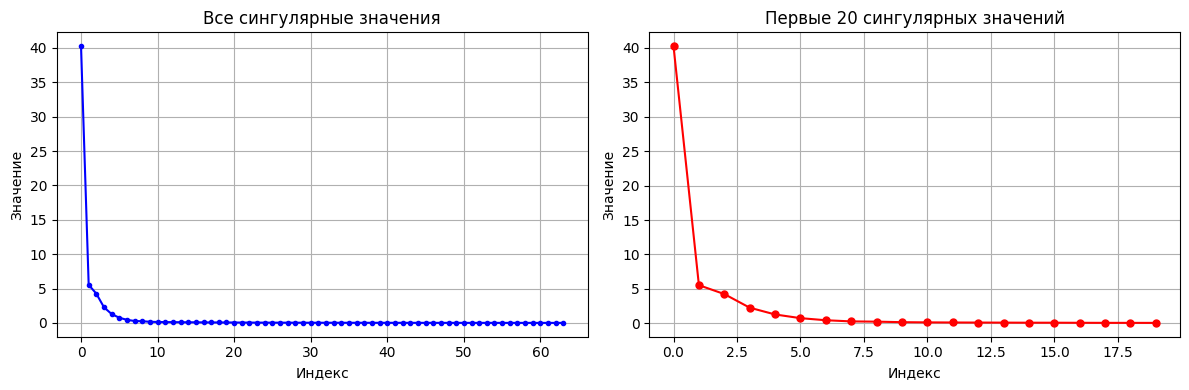

4) Восстанавливаем патч с разным k


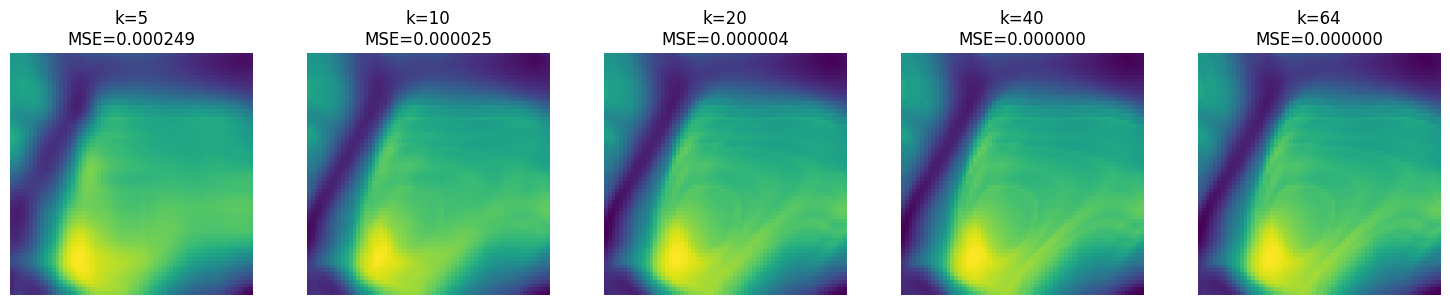

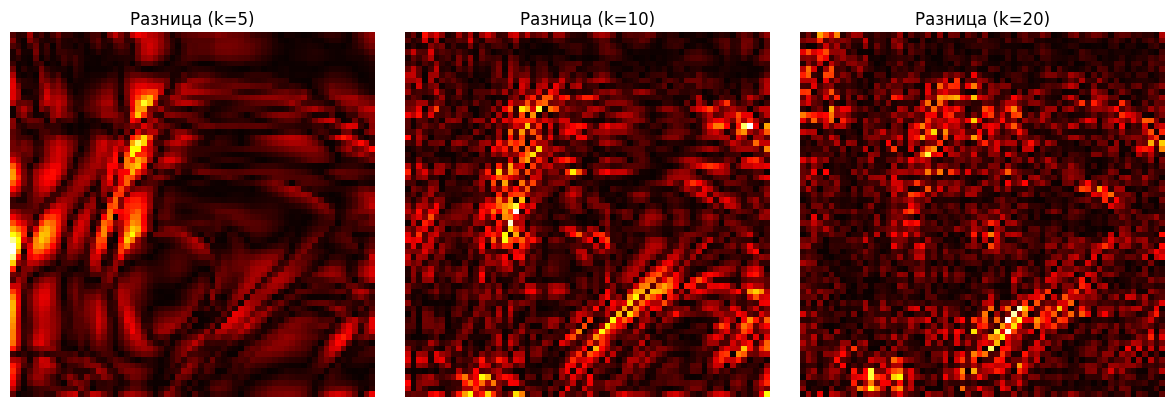

In [ ]:
all_patches_clean = []
all_patches_noisy = []

patch_size = 64
step = 32

for img_idx, img in enumerate(all_images):
    print(f"\nОбработка {img_idx+1} из {len(all_images)}...") #проходит по всем элементам enumerate(...) дает и номер и само изображение. отладка

    img_norm = (img - img.min()) / (img.max() - img.min()) #практическая нормализация
    if img_idx == 0:
        print("\nПосле нормализации:")
        print(f"  Мин: {img_norm.min():.4f}")
        print(f"  Макс: {img_norm.max():.4f}")

        plt.figure(figsize=(6, 6))
        plt.imshow(img_norm, cmap='viridis')
        plt.title("Астрономические данные (нормализованные)")
        plt.colorbar(label="Относительная интенсивность")
        plt.axis('off')
        plt.show()

        plt.figure(figsize=(8, 4)) # гистограмма чтоб узнать сколько пикселей имеют каждое значение
        plt.hist(img_norm.flatten(), bins=100, alpha=0.7)
        plt.title("Распределение значений интенсивности")
        plt.xlabel("Интенсивность")
        plt.ylabel("Количество пикселей")
        plt.yscale('log') # Логарифмическая шкала чтобы было видно маленькие значения
        plt.show()

    h, w = img_norm.shape
    patches_count = 0
    for y in range(0, h - patch_size + 1, step): #верхняя допустимая граница
        for x in range(0, w - patch_size + 1, step):
            patch = img_norm[y:y+patch_size, x:x+patch_size] #само вырезание

            noise = torch.randn(patch.shape) * 0.1 #тензор заполненный случ числами
            noisy_patch = patch + noise.numpy()
            noisy_patch = np.clip(noisy_patch, 0, 1) #обрезаем если вышло за 0 1

            all_patches_clean.append(patch) #таргет
            all_patches_noisy.append(noisy_patch) #вход
            patches_count += 1

    print(f"Создано {patches_count} патчей")

print("ИТОГО:")
print(f"  Изображений: {len(all_images)}")
print(f"  Всего патчей: {len(all_patches_clean)}")
print(f"  Патчей на изображение: ~{len(all_patches_clean) // len(all_images)}")

patch = all_patches_clean[0]

plt.figure(figsize=(4, 4))
plt.imshow(patch, cmap='viridis')
plt.title(f"Тестовый патч (для SVD)")
plt.colorbar(label="Интенсивность")
plt.axis('off')
plt.show()

print('2)применяем svd к патчу')

U,S,Vt = np.linalg.svd(patch, full_matrices=False)  # В numpy S возвращается не как матрица Σ, а как вектор из 64 чисел (диагональ матрицы Σ). full_matrices=False  чтобы экономить память
print(f"U: {U.shape}")
print(f"S: {S.shape}")
print(f"Vt: {Vt.shape}")

def find_elbow(values):
    diffs = np.diff(values) #вычисляет разницу между соседними элементами values
    second_diffs = np.diff(diffs) #помогает найти точку где происходить резкое снижение
    elbow_idx = np.argmax(second_diffs) + 2 # нахоидт индекс самого большого изменения в массиве
    return elbow_idx

k_auto = find_elbow(S) #куда сохраняем результат. вызов функции. вектор s аргумент функции
print(f"Автоматически подобранный k: {k_auto}")
k_used = k_auto  #используемый к (после какого k будем обнулять)
S_k = S.copy() #новый вектор сингулярных значений (с обрезкой) _k = с учётом k. s - 64 сингулярных значения из SVD. copy чтобы не заруинить оригинал
S_k[k_used:] = 0 #срез. обнуляем неважные элементы
patch_svd = U @ np.diag(S_k) @ Vt #np.diag(...)Превращает вектор S_k в диагональную матрицу Σ
print(f"patch_svd создан с k={k_used}")
print(f"  Размер: {patch_svd.shape}")
print(f"  Диапазон: [{patch_svd.min():.4f}, {patch_svd.max():.4f}]") #.min() находит минимальное значение в массиве, max максимальное

psnr_val = psnr(patch, patch_svd) #Числовая оценка качества в децибелах (dB)
ssim_val = ssim(patch, patch_svd, data_range=patch_svd.max() - patch_svd.min()) #оценка сохранения структур (от 0 до 1)

noisy_patch_for_comparison = all_patches_noisy[0]

psnr_noisy = psnr(patch, noisy_patch_for_comparison)
ssim_noisy = ssim(patch, noisy_patch_for_comparison, data_range=noisy_patch_for_comparison.max() - noisy_patch_for_comparison.min())

print(f"\nЗашумлённый патч (для сравнения):")
print(f"PSNR: {psnr_noisy:.2f} dB")
print(f"SSIM: {ssim_noisy:.4f}")

print(f"\n Улучшение после SVD:")
print(f"PSNR: +{psnr_val - psnr_noisy:.2f} dB")
print(f"SSIM: +{ssim_val - ssim_noisy:.4f}")


print(f"\nПервые 10 сингулярных значений:")
for i in range(10):
  print(f'S[{i}] = {S[i]:.6f}')

print(f"\nПоследние 10 сингулярных значений:")
for i in range(len(S)-10, len(S)):
    print(f"  S[{i}] = {S[i]:.8f}")

print("3) визуализируем сингулярные значения")
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(S, 'bo-', markersize=3) # синие кружочки, соединённые линией
plt.title("Все сингулярные значения")
plt.xlabel("Индекс")
plt.ylabel("Значение")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(S[:20], 'ro-', markersize=5) #красные кружочки, соединённые линией
plt.title("Первые 20 сингулярных значений")
plt.xlabel("Индекс")
plt.ylabel("Значение")
plt.grid(True)

plt.tight_layout()
plt.show()

print("4) Восстанавливаем патч с разным k")
k_values = [5, 10, 20, 40, 64]
fig, axes = plt.subplots(1, len(k_values), figsize=(15, 3))

for idx, k in enumerate(k_values): #idx: порядковый номер шага (0, 1, 2...).
    S_k = S.copy()
    S_k[k:] = 0 #то же самое. все элементы от индекса k до самого конца обнулить

    patch_reconstructed = U @ np.diag(S_k) @ Vt

    mse = np.mean((patch - patch_reconstructed)**2) #разница в каждом пикселе (**2 чтобы отрицательные ошибки не компенсировали положительные) и усредняем

    axes[idx].imshow(patch_reconstructed, cmap='viridis')
    axes[idx].set_title(f"k={k}\nMSE={mse:.6f}")
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for idx, k in enumerate([5, 10, 20]):
    S_k = S.copy()
    S_k[k:] = 0
    patch_rec = U @ np.diag(S_k) @ Vt
    difference = np.abs(patch - patch_rec)

    axes[idx].imshow(difference, cmap='hot')
    axes[idx].set_title(f"Разница (k={k})")
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
class MyDenoiser(nn.Module):
  def __init__(self):
    super().__init__() #способ вызвать настройки из базового класса nn.module
    self.enc_conv1 = nn.Conv2d(1, 64, kernel_size=3, padding=1) #сверточныц слой с 1 входным каналом, 64 выходными, размер ядра 3на3, отступ (добавление 0 по краям, чтобы размер выхода сильно не уменьшался)
    self.enc_relu1 = nn.ReLU()
    self.enc_pool1 = nn.MaxPool2d(2) #уменьшает размер картинки. (2) значит что он смотрит на квадратик пикселей 2 на 2 и оставляет толкьо один самый яркий
    self.enc_conv2 = nn.Conv2d(64, 32, kernel_size = 3, padding=1)
    self.enc_relu2 = nn.ReLU()
    self.enc_pool2 = nn.MaxPool2d(2)
    self.bottleneck_conv = nn.Conv2d(32, 64, kernel_size=3, padding=1)
    self.bottleneck_relu = nn.ReLU()

    self.dec_up1 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True) #увеличивает размер изображния. scale_factor картинка станет в два раза выше и шире. bilinear (биленейная интерполяция) метод дорисовывает новые признаки. align_corners=True без него масштаб съезжает
    self.dec_conv1 = nn.Conv2d(64, 32, kernel_size=3, padding=1)
    self.dec_relu1 = nn.ReLU()

    self.dec_up2 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
    self.dec_conv2 = nn.Conv2d(32, 1, kernel_size=3, padding=1)
    self.dec_relu2 = nn.ReLU()


  def forward(self, x):
    x = self.enc_conv1(x)
    x = self.enc_relu1(x)
    x = self.enc_pool1(x)
    x = self.enc_conv2(x)
    x = self.enc_relu2(x)
    x = self.enc_pool2(x)

    x = self.bottleneck_conv(x)
    x = self.bottleneck_relu(x)

    x = self.dec_up1(x)
    x = self.dec_conv1(x)
    x = self.dec_relu1(x)

    x = self.dec_up2(x)
    x = self.dec_conv2(x)
    x = self.dec_relu2(x)
    x = torch.clamp(x, 0, 1) #обрезает значения вне диапазона


    return x

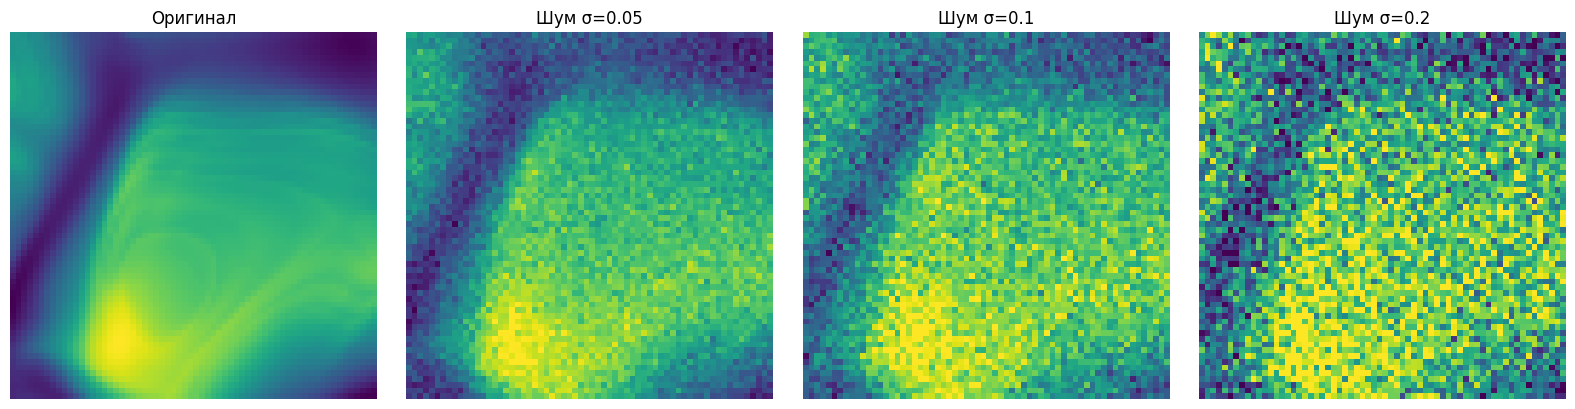

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4)) #1 строка с4 графиками в ряд.fig область для рисования, axes массив сколько всего графиков.16 ширина всей области в дюймах

axes[0].imshow(patch, cmap='viridis')
axes[0].set_title("Оригинал")
axes[0].axis('off') #отключает изображение осей

for idx, sigma in enumerate([0.05, 0.10, 0.20], start=1): #рахзные коэффиценты сигма
    noise = torch.randn(patch.shape) * sigma #массив случайных значений (размер как у патча) * сигма чтобы задать интенсивность шума. тензор(!!)
    noisy = patch + noise.numpy() #преобразовываем тензор в numpy массив
    noisy = np.clip(noisy, 0, 1) #обрезаем значения пиксел1 (больше 1=1, меньше 0=0)

    axes[idx].imshow(noisy, cmap='viridis')
    axes[idx].set_title(f"Шум σ={sigma}")
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

модель создана: 56353 параметров
До обучения: мин=0.0000, макс=0.0001


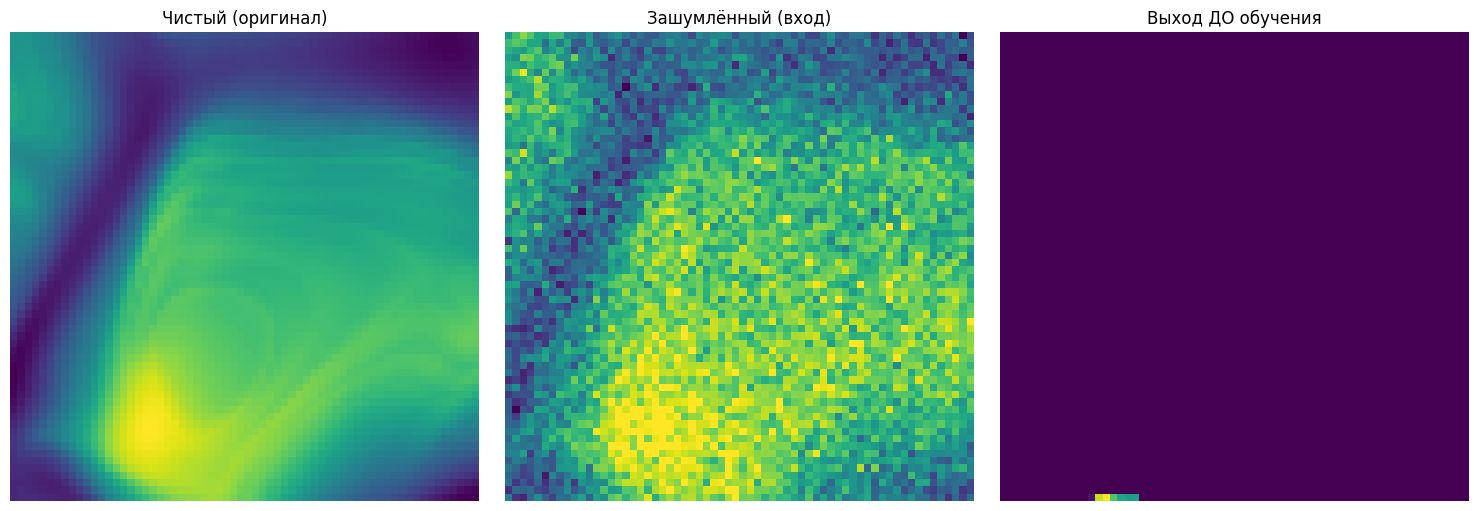

Epoch [10/100], Avg Loss: 0.000782
Epoch [20/100], Avg Loss: 0.000693
Epoch [30/100], Avg Loss: 0.000659
Epoch [40/100], Avg Loss: 0.000650
Epoch [50/100], Avg Loss: 0.000634
Epoch [60/100], Avg Loss: 0.000621
Epoch [70/100], Avg Loss: 0.000617
Epoch [80/100], Avg Loss: 0.000611
Epoch [90/100], Avg Loss: 0.000602
Epoch [100/100], Avg Loss: 0.000594
PSNR: 33.20 dB
SSIM: 0.9162
Мин: 0.2299, Макс: 0.9630


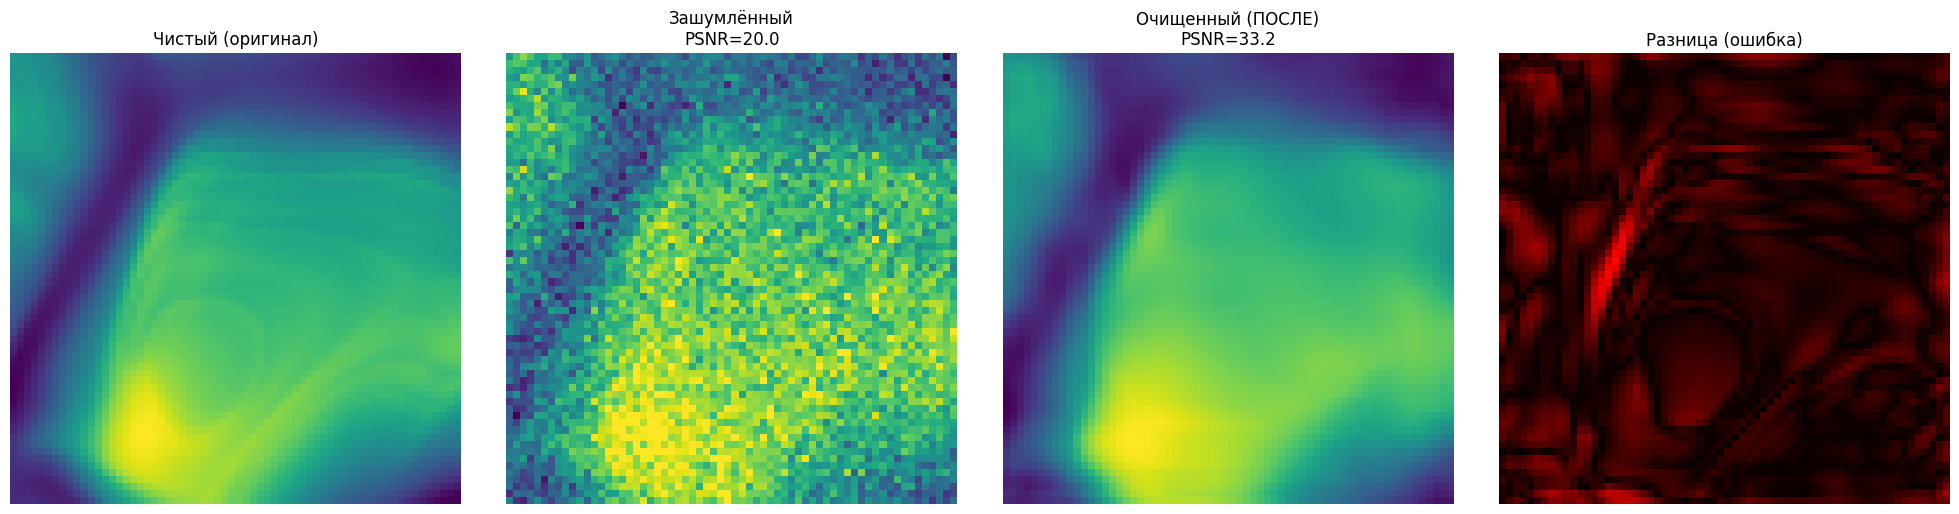


Сравнение: SVD vs CNN
Метод                PSNR (dB)       SSIM           
Зашумлённый          20.02           0.3227         
SVD (k=10)           22.00           0.7676         
CNN                  33.20           0.9162         

 CNN превзошла SVD на 11.21 dB


In [ ]:
model = MyDenoiser()
print(f"модель создана: {sum(p.numel() for p in model.parameters())} параметров")
test_idx = 0
test_clean = all_patches_clean[test_idx] #достаем первую пару картинок
test_noisy = all_patches_noisy[test_idx]

model.eval() #переводит модель в режим оценки(проверка качества без изменения весов). не обучаем
with torch.no_grad(): #смотрим что выдает модель без обучения
    input_test = torch.from_numpy(test_noisy).unsqueeze(0).unsqueeze(0).float() #добавляем каналы (чтобы оптимизировать вычисления).
    output_before = model(input_test).squeeze().numpy()

print(f"До обучения: мин={output_before.min():.4f}, макс={output_before.max():.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(test_clean, cmap='viridis')
axes[0].set_title("Чистый (оригинал)")
axes[0].axis('off')

axes[1].imshow(test_noisy, cmap='viridis')
axes[1].set_title("Зашумлённый (вход)")
axes[1].axis('off')

axes[2].imshow(output_before, cmap='viridis')
axes[2].set_title("Выход ДО обучения")
axes[2].axis('off')

plt.tight_layout()
plt.show()

criterion = nn.MSELoss() #штрафует за большие отклонения
optimizer = optim.Adam(model.parameters(), lr=0.001)

for epoch in range(100):
    total_loss = 0

    for i in range(len(all_patches_clean)):
        patch = all_patches_clean[i]
        noisy_patch = all_patches_noisy[i]

        input_tensor = torch.from_numpy(noisy_patch).unsqueeze(0).unsqueeze(0).float() #превращаем в тензоры, добавляем размерности
        target_tensor = torch.from_numpy(patch).unsqueeze(0).unsqueeze(0).float()

        optimizer.zero_grad() #стирает прошлую ошибку в памяти (потому что оптимизатор должен понимать как поменять параментры на основе текущей ошибки)
        output = model(input_tensor) #проход данных через модель
        loss = criterion(output, target_tensor) #насколько отличается от оригинала
        loss.backward() #расчет градиентов
        optimizer.step() #обновляем веса

        total_loss += loss.item()

    if (epoch + 1) % 10 == 0: #выводим ошибку каждые 10 эпох
        avg_loss = total_loss / len(all_patches_clean)
        print(f'Epoch [{epoch+1}/100], Avg Loss: {avg_loss:.6f}')


model.eval() #режим оценки
with torch.no_grad(): #менеждер контекста. просто смотреть результат
    output_after = model(input_test).squeeze().numpy()

psnr_after = psnr(test_clean, output_after)
ssim_after = ssim(test_clean, output_after, data_range=output_after.max() - output_after.min())

print(f"PSNR: {psnr_after:.2f} dB")
print(f"SSIM: {ssim_after:.4f}")
print(f"Мин: {output_after.min():.4f}, Макс: {output_after.max():.4f}")

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(test_clean, cmap='viridis')
axes[0].set_title("Чистый (оригинал)")
axes[0].axis('off')

axes[1].imshow(test_noisy, cmap='viridis')
axes[1].set_title(f"Зашумлённый\nPSNR={psnr(test_clean, test_noisy):.1f}")
axes[1].axis('off')

axes[2].imshow(output_after, cmap='viridis')
axes[2].set_title(f"Очищенный (ПОСЛЕ)\nPSNR={psnr_after:.1f}")
axes[2].axis('off')

difference = np.abs(test_clean - output_after)
axes[3].imshow(difference, cmap='hot', vmin=0, vmax=0.3)
axes[3].set_title("Разница (ошибка)")
axes[3].axis('off')

plt.tight_layout()
plt.show()
output_dir = '/content/drive/MyDrive/models' #пока не работает
os.makedirs(output_dir, exist_ok=True)

torch.save({
    'epoch': 100,
    'model_state_dict': model.state_dict(), #словарь где хранятся веса и смещение
    'optimizer_state_dict': optimizer.state_dict(),
    'loss': loss,
}, os.path.join(output_dir, 'denoiser_cnn_epoch100.pth')) #соединяет название папки с именем файла. output_dir переменная с названием папки куда сохраняем модель, .pth расширение pytorch

print('\nСравнение: SVD vs CNN')
print(f"{('Метод'):<20} {('PSNR (dB)'):<15} {('SSIM'):<15}")
print(f"{('Зашумлённый'):<20} {psnr(test_clean, test_noisy):<15.2f} {ssim(test_clean, test_noisy, data_range=1.0):<15.4f}")
print(f"{('SVD (k=10)'):<20} {psnr_val:<15.2f} {ssim_val:<15.4f}")
print(f"{('CNN'):<20} {psnr_after:<15.2f} {ssim_after:<15.4f}") #форматирование результатов

if psnr_after > psnr_val:
    print(f"\n CNN превзошла SVD на {psnr_after - psnr_val:.2f} dB")
else:
    print(f"\n SVD лучше на {psnr_val - psnr_after:.2f} dB")

In [ ]:
U_noisy, S_noisy, Vt_noisy = np.linalg.svd(test_noisy, full_matrices=False) #компактные матрицы без лишних нулей
S_hybrid = S_noisy.copy()
S_hybrid[10:] = 0  #жесткое ограничесние, потом сделаю k автоматическое
patch_svd_input = U_noisy @ np.diag(S_hybrid) @ Vt_noisy

with torch.no_grad(): #контекстный менеджер
    input_hybrid = torch.from_numpy(patch_svd_input).unsqueeze(0).unsqueeze(0).float()
    output_hybrid = model(input_hybrid).squeeze().numpy()

psnr_hybrid = psnr(test_clean, output_hybrid)
ssim_hybrid = ssim(test_clean, output_hybrid, data_range=output_hybrid.max() - output_hybrid.min())

print(f"Гибридный подход (SVD→CNN):")
print(f"PSNR: {psnr_hybrid:.2f} dB")
print(f"SSIM: {ssim_hybrid:.4f}")

print(f"{('Метод'):<25} {('PSNR (dB)'):<15} {('SSIM'):<15} {('Улучшение'):<15}")
print("-" * 70)
print(f"{('Зашумлённый'):<25} {psnr_noisy:<15.2f} {ssim_noisy:<15.4f} {('-'):<15}")
print(f"{('SVD (k=10)'):<25} {psnr_val:<15.2f} {ssim_val:<15.4f} {('+' + str(round(psnr_val - psnr_noisy, 1)) + ' dB'):<15}")
print(f"{('CNN'):<25} {psnr_after:<15.2f} {ssim_after:<15.4f} {('+' + str(round(psnr_after - psnr_noisy, 1)) + ' dB'):<15}")
print(f"{('SVD → CNN (гибрид)'):<25} {psnr_hybrid:<15.2f} {ssim_hybrid:<15.4f} {('+' + str(round(psnr_hybrid - psnr_noisy, 1)) + ' dB'):<15}")

methods = {
    'SVD': psnr_val,
    'CNN': psnr_after,
    'SVD→CNN': psnr_hybrid
}
best_method = max(methods, key=methods.get)
print(f"\n ЛУЧШИЙ МЕТОД: {best_method} (PSNR = {methods[best_method]:.2f} dB)")

Гибридный подход (SVD→CNN):
PSNR: 32.10 dB
SSIM: 0.9132
Метод                     PSNR (dB)       SSIM            Улучшение      
----------------------------------------------------------------------
Зашумлённый               20.02           0.3227          -              
SVD (k=10)                22.00           0.7676          +2.0 dB        
CNN                       33.20           0.9162          +13.2 dB       
SVD → CNN (гибрид)        32.10           0.9132          +12.1 dB       

 ЛУЧШИЙ МЕТОД: CNN (PSNR = 33.20 dB)


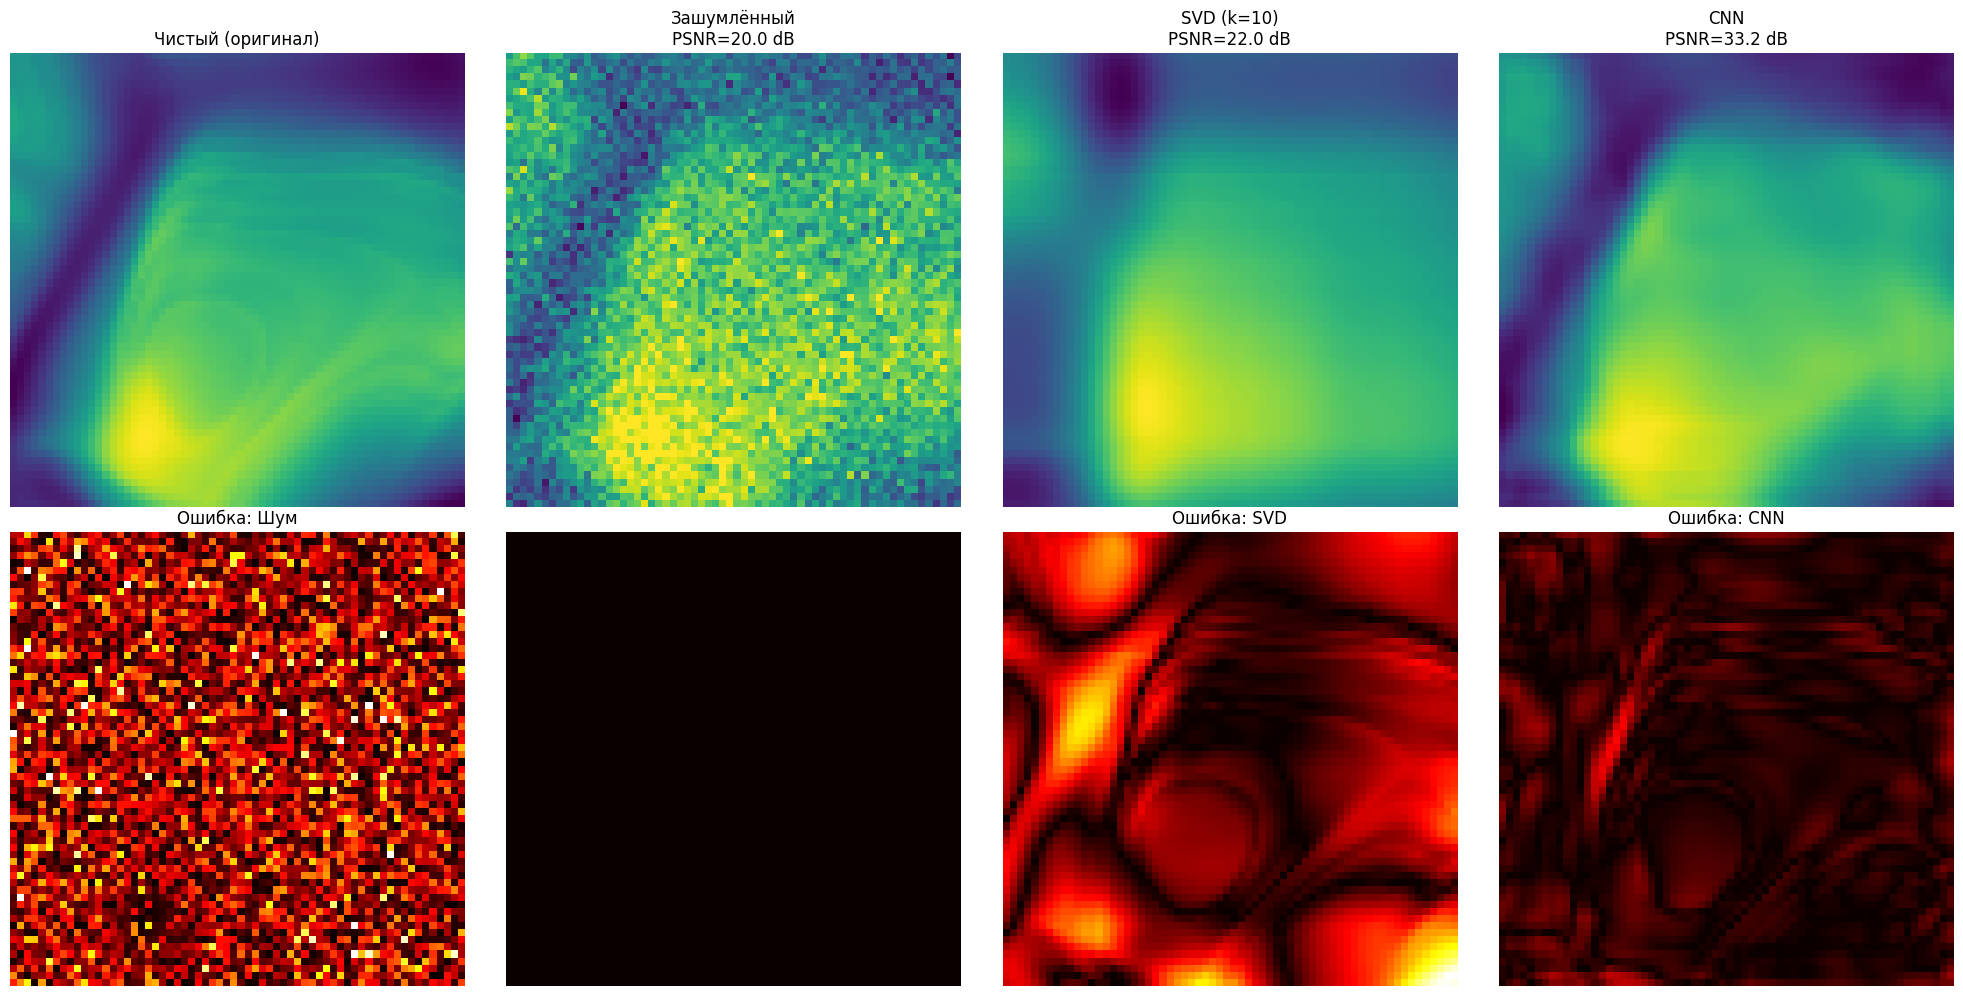

In [ ]:
with torch.no_grad():
    output_cnn_viz = model(torch.from_numpy(test_noisy).unsqueeze(0).unsqueeze(0).float()).squeeze().numpy()

fig, axes = plt.subplots(2, 4, figsize=(20, 10))

axes[0, 0].imshow(test_clean, cmap='viridis')
axes[0, 0].set_title("Чистый (оригинал)")
axes[0, 0].axis('off')

axes[0, 1].imshow(test_noisy, cmap='viridis')
axes[0, 1].set_title(f"Зашумлённый\nPSNR={psnr_noisy:.1f} dB")
axes[0, 1].axis('off')

axes[0, 2].imshow(patch_svd, cmap='viridis')
axes[0, 2].set_title(f"SVD (k=10)\nPSNR={psnr_val:.1f} dB")
axes[0, 2].axis('off')

axes[0, 3].imshow(output_cnn_viz, cmap='viridis')
axes[0, 3].set_title(f"CNN\nPSNR={psnr_after:.1f} dB")
axes[0, 3].axis('off')

diff_noisy = np.abs(test_clean - test_noisy)
diff_svd = np.abs(test_clean - patch_svd)
diff_cnn = np.abs(test_clean - output_cnn_viz)

axes[1, 0].imshow(diff_noisy, cmap='hot', vmin=0, vmax=0.3)
axes[1, 0].set_title("Ошибка: Шум")
axes[1, 0].axis('off')

axes[1, 1].imshow(np.zeros_like(diff_noisy), cmap='hot')  #пока что пустой для симметрии но потом добавлю карту ошибки для гибридного метода
axes[1, 1].axis('off')

axes[1, 2].imshow(diff_svd, cmap='hot', vmin=0, vmax=0.3)
axes[1, 2].set_title(f"Ошибка: SVD")
axes[1, 2].axis('off')

axes[1, 3].imshow(diff_cnn, cmap='hot', vmin=0, vmax=0.3)
axes[1, 3].set_title(f"Ошибка: CNN")
axes[1, 3].axis('off')

plt.tight_layout()
plt.show()


 Используем очищенные изображения:
  Оригинал (шумный): PSNR = 20.02 dB
  SVD (k=10): PSNR = 22.00 dB 
  CNN: PSNR = 33.20 dB

1 Детектор границ (Canny)...
  Зашумлённый: найдено границ ~104 пикселей
  SVD: найдено границ ~109 пикселей
  CNN: найдено границ ~162 пикселей
  Чистый: найдено границ ~153 пикселей

2 Детектор объектов (DoG - Difference of Gaussians)...
  Зашумлённый: найдено 141 объектов
  SVD: найдено 7 объектов 
  CNN: найдено 8 объектов
  Чистый (эталон): 10 объектов

3 Пороговая сегментация
  Зашумлённый: 2791 ярких пикселей
  SVD: 2926 ярких пикселей
  CNN: 2831 ярких пикселей
  Чистый: 2819 ярких пикселей (эталон)

4 Визуализация результатов...


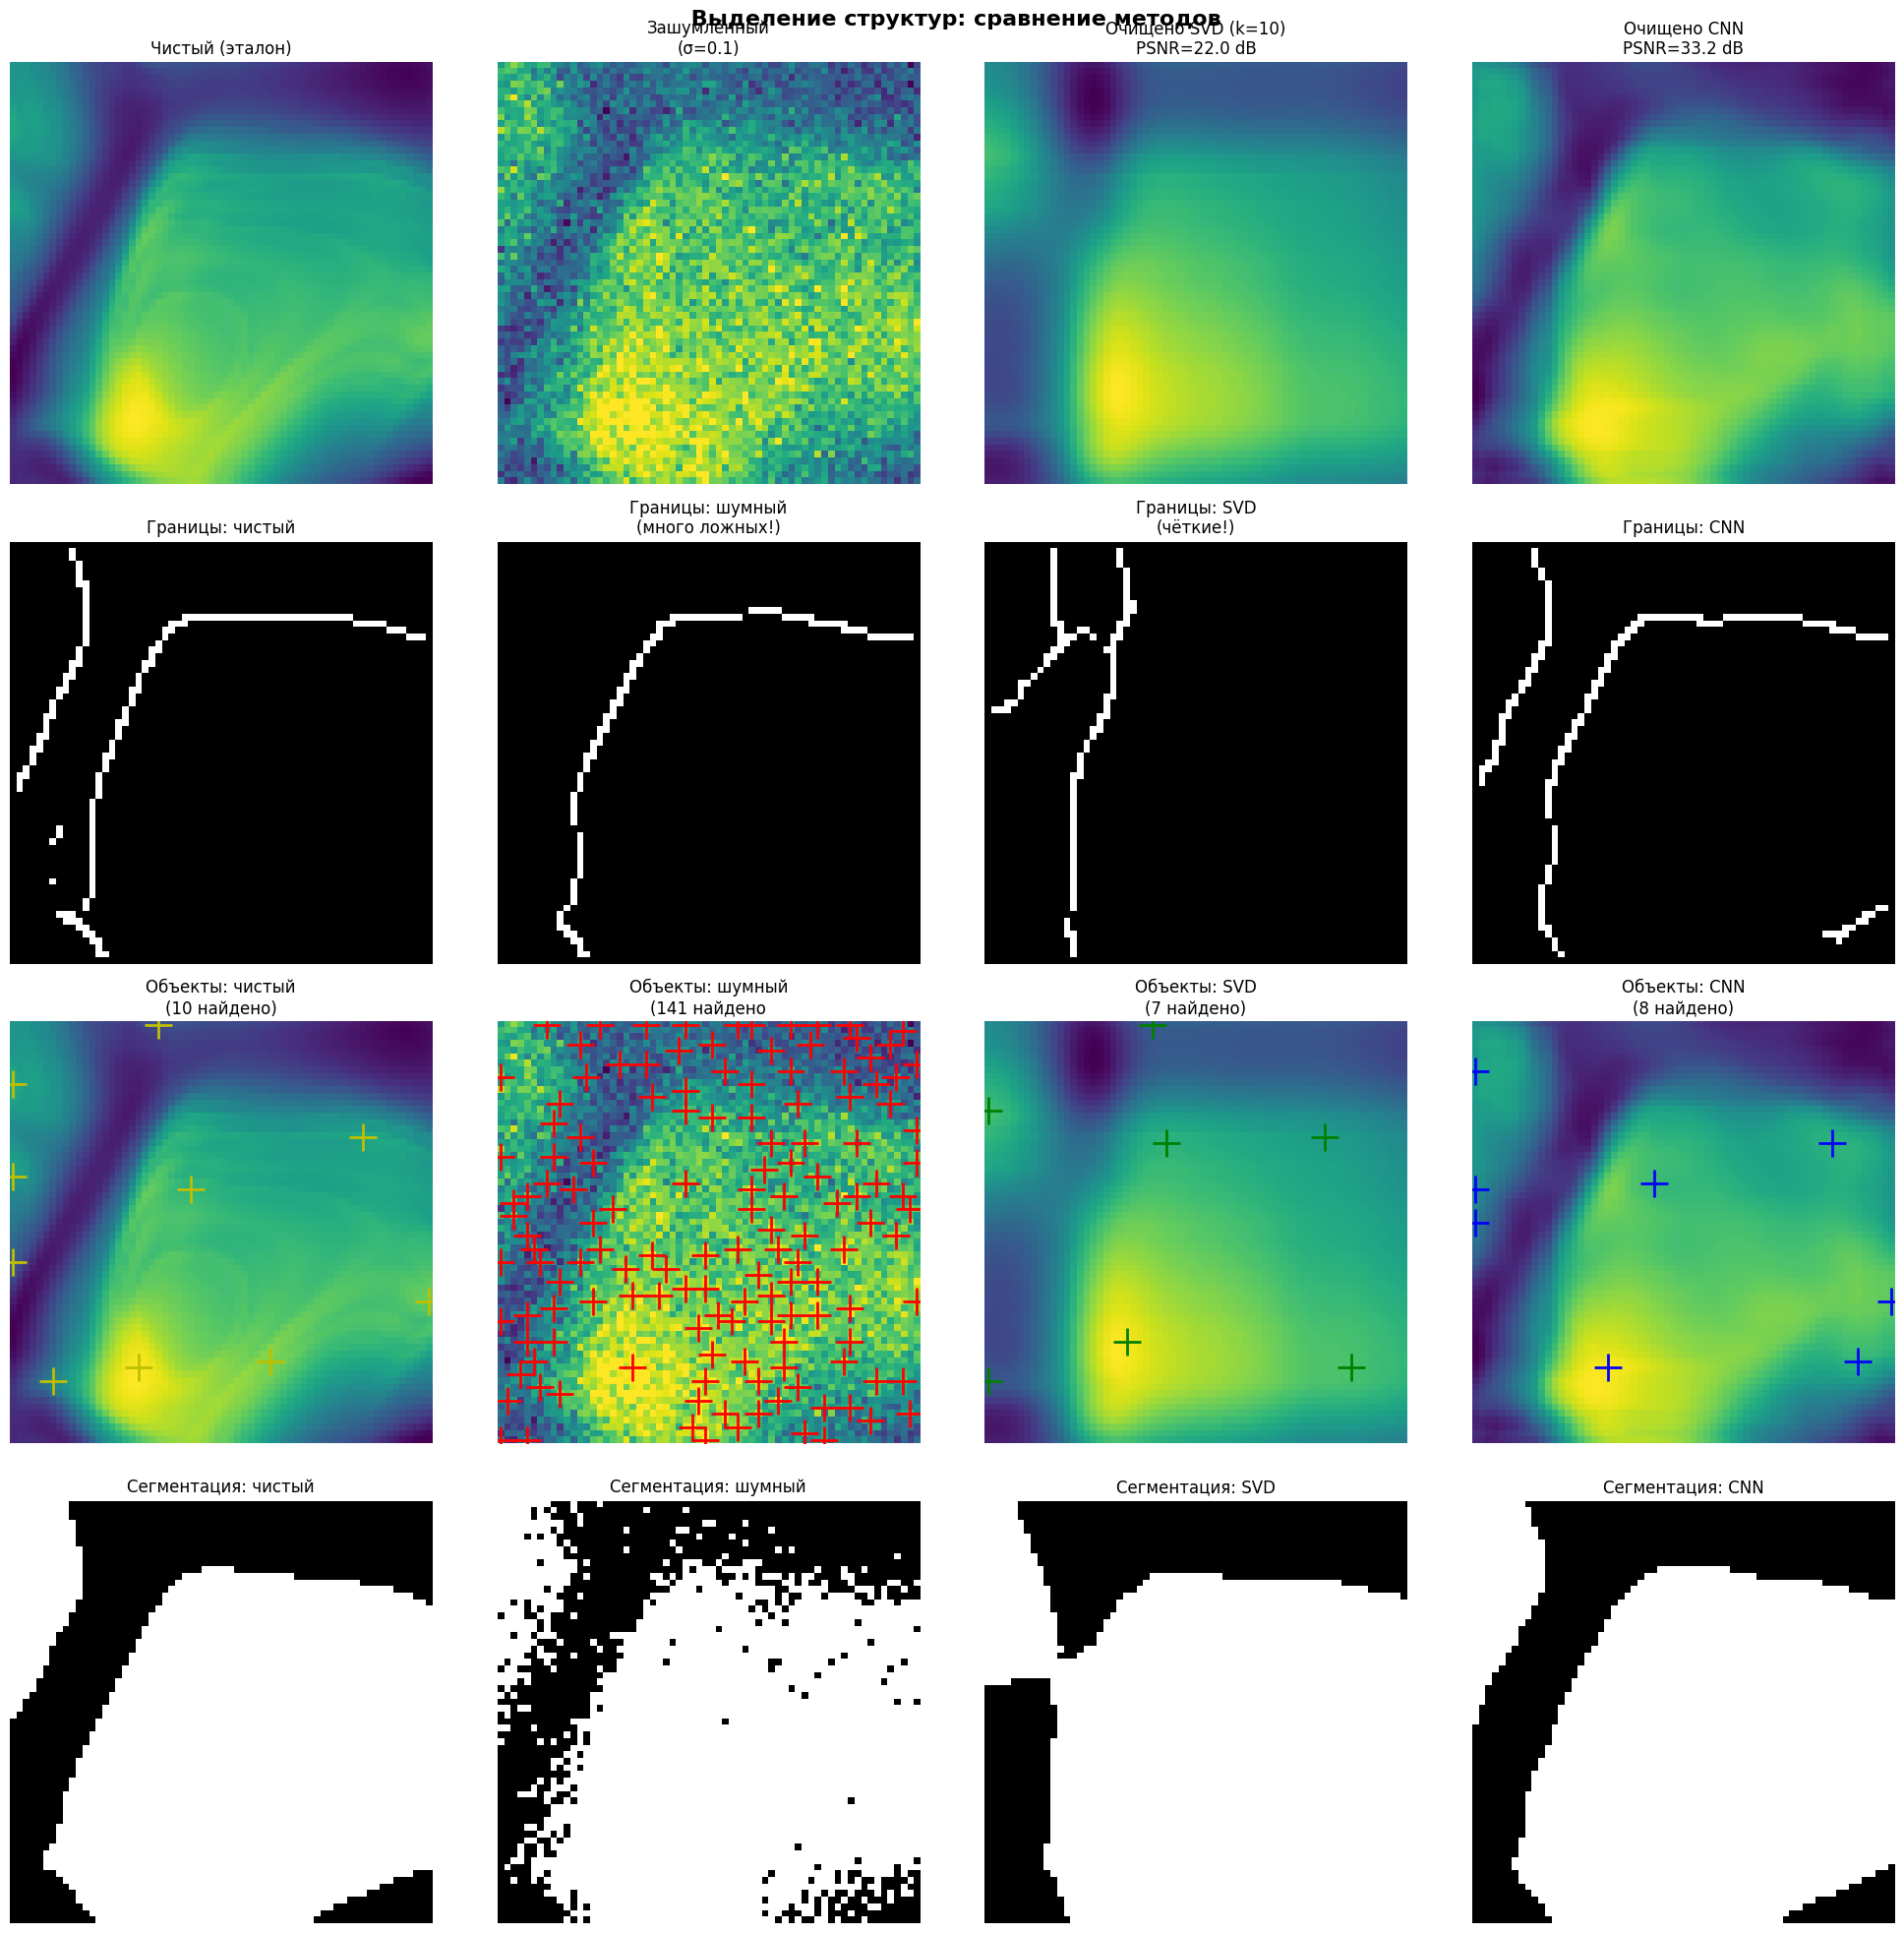


5 Количественная оценка...

Точность детекции (относительно чистого изображения):
Метод           Границы (IoU)        Сегментация (IoU)   
-------------------------------------------------------
SVD             0.1441               0.8886              
CNN             0.3816               0.9776              
ФИНАЛЬНЫЕ ВЫВОДЫ ЭТАПА 5:

Для выделения структур ЛУЧШЕ подходит: CNN
   Причина: Лучше восстанавливает детали

 Ключевые метрики:
   PSNR SVD: 22.00 dB (+2.0 dB vs шум)
   PSNR CNN: 33.20 dB (+13.2 dB vs шум)
   Точность границ (SVD): 14.4%
   Точность сегментации (SVD): 88.9%


In [ ]:
print("\n Используем очищенные изображения:")
print(f"  Оригинал (шумный): PSNR = {psnr_noisy:.2f} dB")
print(f"  SVD (k=10): PSNR = {psnr_val:.2f} dB ")
print(f"  CNN: PSNR = {psnr_after:.2f} dB")

test_patch_clean = all_patches_clean[0]
test_patch_noisy = all_patches_noisy[0]
test_patch_svd = patch_svd
test_patch_cnn = output_after

print("\n1 Детектор границ (Canny)...")

sigma_noisy = 3.0   #параметр отвечает за размытие картинки
sigma_clean = 2.0

edges_noisy = canny(test_patch_noisy, sigma=sigma_noisy, low_threshold=0.1, high_threshold=0.3) #контуры на зашумленном изображении. low(high)_threshold=... нижняя и верхняя граница чувствительности. серая зона - смотрит, не связаны ли эти точки с сильными границами
edges_svd = canny(test_patch_svd, sigma=sigma_clean, low_threshold=0.1, high_threshold=0.3)
edges_cnn = canny(test_patch_cnn, sigma=sigma_clean, low_threshold=0.1, high_threshold=0.3)
edges_clean = canny(test_patch_clean, sigma=sigma_clean, low_threshold=0.1, high_threshold=0.3)

print(f"  Зашумлённый: найдено границ ~{np.sum(edges_noisy)} пикселей")
print(f"  SVD: найдено границ ~{np.sum(edges_svd)} пикселей")
print(f"  CNN: найдено границ ~{np.sum(edges_cnn)} пикселей")
print(f"  Чистый: найдено границ ~{np.sum(edges_clean)} пикселей")

print("\n2 Детектор объектов (DoG - Difference of Gaussians)...") #метод ищет объекты похожие на пятна. вычитае одну размытую картинку из другой более резкой

min_sigma = 1  #минимальный размер пятна которое мы ищем
max_sigma = 10
threshold = 0.02 #чтобы отсеивать слабые пятна

def count_blobs(image, min_sig, max_sig, thresh): #принимает картинку, параметры сигма и порог
    try:
        blobs = blob_dog(image, min_sigma=min_sig, max_sigma=max_sig, threshold=thresh) #находит объекты
        return len(blobs), blobs
    except:
        return 0, np.array([])

n_blobs_noisy, blobs_noisy = count_blobs(test_patch_noisy, min_sigma, max_sigma, threshold) #count_blobs возвращает кол.во объектов и координаты
n_blobs_svd, blobs_svd = count_blobs(test_patch_svd, min_sigma, max_sigma, threshold)
n_blobs_cnn, blobs_cnn = count_blobs(test_patch_cnn, min_sigma, max_sigma, threshold)
n_blobs_clean, blobs_clean = count_blobs(test_patch_clean, min_sigma, max_sigma, threshold)

print(f"  Зашумлённый: найдено {n_blobs_noisy} объектов")
print(f"  SVD: найдено {n_blobs_svd} объектов ")
print(f"  CNN: найдено {n_blobs_cnn} объектов")
print(f"  Чистый (эталон): {n_blobs_clean} объектов")

print("\n3 Пороговая сегментация") #выделение ярких областей

threshold_val = 0.5

mask_noisy = test_patch_noisy > threshold_val #векторизованная операция в pytorch
mask_svd = test_patch_svd > threshold_val
mask_cnn = test_patch_cnn > threshold_val
mask_clean = test_patch_clean > threshold_val

print(f"  Зашумлённый: {np.sum(mask_noisy)} ярких пикселей")
print(f"  SVD: {np.sum(mask_svd)} ярких пикселей")
print(f"  CNN: {np.sum(mask_cnn)} ярких пикселей")
print(f"  Чистый: {np.sum(mask_clean)} ярких пикселей (эталон)")

print("\n4 Визуализация результатов...")

fig, axes = plt.subplots(4, 4, figsize=(20, 20))
fig.suptitle(' Выделение структур: сравнение методов', fontsize=16, fontweight='bold')

axes[0, 0].imshow(test_patch_clean, cmap='viridis')
axes[0, 0].set_title("Чистый (эталон)")
axes[0, 0].axis('off')

axes[0, 1].imshow(test_patch_noisy, cmap='viridis')
axes[0, 1].set_title(f"Зашумлённый\n(σ=0.1)")
axes[0, 1].axis('off')

axes[0, 2].imshow(test_patch_svd, cmap='viridis')
axes[0, 2].set_title(f"Очищено SVD (k=10)\nPSNR={psnr_val:.1f} dB")
axes[0, 2].axis('off')

axes[0, 3].imshow(test_patch_cnn, cmap='viridis')
axes[0, 3].set_title(f"Очищено CNN\nPSNR={psnr_after:.1f} dB")
axes[0, 3].axis('off')

axes[1, 0].imshow(edges_clean, cmap='gray')
axes[1, 0].set_title("Границы: чистый")
axes[1, 0].axis('off')

axes[1, 1].imshow(edges_noisy, cmap='gray')
axes[1, 1].set_title(f"Границы: шумный\n(много ложных!)")
axes[1, 1].axis('off')

axes[1, 2].imshow(edges_svd, cmap='gray')
axes[1, 2].set_title(f"Границы: SVD\n(чёткие!)")
axes[1, 2].axis('off')

axes[1, 3].imshow(edges_cnn, cmap='gray')
axes[1, 3].set_title(f"Границы: CNN")
axes[1, 3].axis('off')

axes[2, 0].imshow(test_patch_clean, cmap='viridis')
axes[2, 0].plot(blobs_clean[:, 1], blobs_clean[:, 0], 'y+', markersize=20, markeredgewidth=2)
axes[2, 0].set_title(f"Объекты: чистый\n({n_blobs_clean} найдено)")
axes[2, 0].axis('off')

axes[2, 1].imshow(test_patch_noisy, cmap='viridis')
axes[2, 1].plot(blobs_noisy[:, 1], blobs_noisy[:, 0], 'r+', markersize=20, markeredgewidth=2)
axes[2, 1].set_title(f"Объекты: шумный\n({n_blobs_noisy} найдено")
axes[2, 1].axis('off')

axes[2, 2].imshow(test_patch_svd, cmap='viridis')
axes[2, 2].plot(blobs_svd[:, 1], blobs_svd[:, 0], 'g+', markersize=20, markeredgewidth=2)
axes[2, 2].set_title(f"Объекты: SVD\n({n_blobs_svd} найдено)")
axes[2, 2].axis('off')

axes[2, 3].imshow(test_patch_cnn, cmap='viridis')
axes[2, 3].plot(blobs_cnn[:, 1], blobs_cnn[:, 0], 'b+', markersize=20, markeredgewidth=2)
axes[2, 3].set_title(f"Объекты: CNN\n({n_blobs_cnn} найдено)")
axes[2, 3].axis('off')

axes[3, 0].imshow(mask_clean, cmap='gray')
axes[3, 0].set_title(f"Сегментация: чистый")
axes[3, 0].axis('off')

axes[3, 1].imshow(mask_noisy, cmap='gray')
axes[3, 1].set_title(f"Сегментация: шумный")
axes[3, 1].axis('off')

axes[3, 2].imshow(mask_svd, cmap='gray')
axes[3, 2].set_title(f"Сегментация: SVD")
axes[3, 2].axis('off')

axes[3, 3].imshow(mask_cnn, cmap='gray')
axes[3, 3].set_title(f"Сегментация: CNN")
axes[3, 3].axis('off')

plt.tight_layout()
plt.show()

print("\n5 Количественная оценка...")

def detection_accuracy(detected, reference): #чтобы считать iou
    if len(reference) == 0: #эталон (маска чистого изображения)
        return 1.0 if len(detected) == 0 else 0.0
    intersection = np.logical_and(detected, reference).sum() #logical_and находим пересечение
    union = np.logical_or(detected, reference).sum() #функция объеденения
    return intersection / union if union > 0 else 1.0 #чтобы получить iou

acc_edges_svd = detection_accuracy(edges_svd, edges_clean)
acc_edges_cnn = detection_accuracy(edges_cnn, edges_clean)

acc_mask_svd = detection_accuracy(mask_svd, mask_clean)
acc_mask_cnn = detection_accuracy(mask_cnn, mask_clean)

print(f"\nТочность детекции (относительно чистого изображения):")
print(f"{'Метод':<15} {'Границы (IoU)':<20} {'Сегментация (IoU)':<20}")
print(f"{'SVD':<15} {acc_edges_svd:<20.4f} {acc_mask_svd:<20.4f}")
print(f"{'CNN':<15} {acc_edges_cnn:<20.4f} {acc_mask_cnn:<20.4f}")


print("ФИНАЛЬНЫЕ ВЫВОДЫ ЭТАПА 5:")

if acc_edges_svd > acc_edges_cnn and acc_mask_svd > acc_mask_cnn:
    best_method = "SVD"
    reason = "Лучше сохраняет структуры и убирает шум"
elif acc_edges_cnn > acc_edges_svd and acc_mask_cnn > acc_mask_svd:
    best_method = "CNN"
    reason = "Лучше восстанавливает детали"
else:
    best_method = "SVD"
    reason = "Стабильнее результат"

print(f"\nДля выделения структур ЛУЧШЕ подходит: {best_method}")
print(f"   Причина: {reason}")

print(f"\n Ключевые метрики:")
print(f"   PSNR SVD: {psnr_val:.2f} dB (+{psnr_val - psnr_noisy:.1f} dB vs шум)")
print(f"   PSNR CNN: {psnr_after:.2f} dB (+{psnr_after - psnr_noisy:.1f} dB vs шум)")
print(f"   Точность границ (SVD): {acc_edges_svd*100:.1f}%")
print(f"   Точность сегментации (SVD): {acc_mask_svd*100:.1f}%")

